# Challenge 2 — Bakai's Models

This notebook evaluates **Decision Tree, Random Forest, and Gradient Boosting** for predicting `Revenue`.

It follows the team's shared evaluation setup:
- the same `preprocessor` structure (StandardScaler + OneHotEncoder);
- `StratifiedGroupKFold` with 5 folds, shuffle, and `random_state=42`;
- `f1_positive`, which scores the positive class `Revenue=True`.

**Run this notebook from the `challenge2` folder** or from the repository root. The data-loading cell checks both locations. Do not use the test set for model selection or tuning.


## 1. Imports and reproducibility

In [1]:
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.metrics import (
    f1_score, precision_score, recall_score,
    ConfusionMatrixDisplay, classification_report
)
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier

warnings.filterwarnings("ignore", category=UserWarning)
RANDOM_STATE = 42


## 2. Load training data

In [2]:
# Works whether Jupyter is launched from the repository root or from challenge2/
candidate_paths = [
    Path("challenge2_train.csv"),
    Path("challenge2/challenge2_train.csv"),
]
train_path = next((p for p in candidate_paths if p.exists()), None)

if train_path is None:
    raise FileNotFoundError(
        "Could not find challenge2_train.csv. Put it in the challenge2 folder "
        "or launch Jupyter from that folder."
    )

train_df = pd.read_csv(train_path)
print("Loaded:", train_path)
print("Training shape:", train_df.shape)
display(train_df.head())


Loaded: challenge2_train.csv
Training shape: (9247, 19)


,ID,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,1,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,3,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
2,4,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
3,7,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.4,Feb,2,4,3,3,Returning_Visitor,False,False
4,9,0,0.0,0,0.0,2,37.000000,0.00,0.10,0.0,0.8,Feb,2,2,2,3,Returning_Visitor,False,False


## 3. Inspect target and prepare shared features

In [3]:
if "Revenue" not in train_df.columns:
    raise ValueError("The training file must contain the Revenue target.")
if "ID" not in train_df.columns:
    raise ValueError("The training file must contain the ID column.")

print("Missing values:", int(train_df.isna().sum().sum()))
print("Duplicate IDs:", int(train_df["ID"].duplicated().sum()))

target_summary = train_df["Revenue"].value_counts(dropna=False).to_frame("Count")
target_summary["Percent"] = (target_summary["Count"] / len(train_df) * 100).round(2)
display(target_summary)

X = train_df.drop(columns=["ID", "Revenue"])
y = train_df["Revenue"].astype(bool)

categorical_features = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend",
]
missing_categorical = [c for c in categorical_features if c not in X.columns]
if missing_categorical:
    raise ValueError(f"Expected categorical columns are missing: {missing_categorical}")

numeric_features = X.columns.difference(categorical_features, sort=False).tolist()

# Shared preprocessing definition from the team's preprocessing notebook.
preprocessor = ColumnTransformer([
    ("numeric", StandardScaler(), numeric_features),
    (
        "categorical",
        OneHotEncoder(handle_unknown="ignore", sparse_output=False),
        categorical_features,
    ),
])

print("Feature matrix:", X.shape)
print("Numeric features:", len(numeric_features))
print("Categorical features:", len(categorical_features))


Missing values: 0
Duplicate IDs: 0


,Count,Percent
Revenue,,
False,7816,84.52
True,1431,15.48


Feature matrix: (9247, 17)
Numeric features: 10
Categorical features: 7


## 4. Shared grouped cross-validation and positive-class F1

In [4]:
from sklearn.metrics import make_scorer

# Keep sessions with identical feature values in the same fold.
groups = pd.util.hash_pandas_object(X, index=False)

splitter = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
cv = list(splitter.split(X, y, groups=groups))

f1_positive = make_scorer(
    f1_score,
    pos_label=True,
    zero_division=0
)

fold_summary = pd.DataFrame([
    {
        "Fold": fold,
        "Validation rows": len(val_idx),
        "Purchase rate (%)": round(100 * y.iloc[val_idx].mean(), 2),
    }
    for fold, (_, val_idx) in enumerate(cv, start=1)
])
display(fold_summary)

print("CV folds:", len(cv))
print("Validation fold sizes:", [len(val_idx) for _, val_idx in cv])


,Fold,Validation rows,Purchase rate (%)
0,1,1850,15.46
1,2,1849,15.47
2,3,1850,15.51
3,4,1849,15.47
4,5,1849,15.47


CV folds: 5
Validation fold sizes: [1850, 1849, 1850, 1849, 1849]


## 5. Define and evaluate baseline models

Each estimator is placed in a Pipeline so preprocessing is fitted only on the training portion of each fold. We report mean train and validation F1 to help identify overfitting.

In [5]:
models = {
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=300,
        random_state=RANDOM_STATE,
        n_jobs=1
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=RANDOM_STATE
    ),
}

baseline_pipelines = {
    name: Pipeline([
        ("preprocess", preprocessor),
        ("clf", estimator),
    ])
    for name, estimator in models.items()
}

baseline_rows = []
baseline_times = {}
for name, pipe in baseline_pipelines.items():
    start = time.perf_counter()
    scores = cross_validate(
        pipe,
        X,
        y,
        cv=cv,
        scoring=f1_positive,
        return_train_score=True,
        n_jobs=-1,
    )
    elapsed = time.perf_counter() - start
    baseline_times[name] = elapsed

    train_f1 = scores["train_score"].mean()
    val_f1 = scores["test_score"].mean()
    baseline_rows.append({
        "Model": name,
        "Train F1": train_f1,
        "CV F1": val_f1,
        "Train-CV gap": train_f1 - val_f1,
        "CV F1 std": scores["test_score"].std(),
        "Time (s)": elapsed,
    })

baseline_results = (
    pd.DataFrame(baseline_rows)
    .sort_values("CV F1", ascending=False)
    .reset_index(drop=True)
)
display(baseline_results.style.format({
    "Train F1": "{:.4f}",
    "CV F1": "{:.4f}",
    "Train-CV gap": "{:.4f}",
    "CV F1 std": "{:.4f}",
    "Time (s)": "{:.1f}",
}))


,Model,Train F1,CV F1,Train-CV gap,CV F1 std,Time (s)
0,Gradient Boosting,0.7342,0.6697,0.0644,0.0181,1.8
1,Random Forest,1.0000,0.6338,0.3662,0.0232,2.1
2,Decision Tree,1.0000,0.5716,0.4284,0.0334,1.4


## 6. Tune the tree-based models with Grid Search

GridSearchCV is run for all three models with the same `cv` folds and `f1_positive` scorer. The test set is not used.

- **Decision Tree:** the baseline tree memorizes the training data (train F1 = 1.000), so the grid limits the depth and the leaf size and also tries balanced class weights.
- **Random Forest:** number of trees, depth, leaf size, and class weights.
- **Gradient Boosting:** number of trees, learning rate, tree depth, and subsampling. The grid contains the default configuration (100 trees, learning rate 0.1, depth 3, no subsampling), so the tuned model cannot score below the baseline.

In [6]:
param_grids = {
    "Decision Tree": {
        "clf__max_depth": [None, 4, 6, 8, 16],
        "clf__min_samples_leaf": [1, 3, 10, 30],
        "clf__class_weight": [None, "balanced"],
    },
    "Random Forest": {
        "clf__n_estimators": [200, 400],
        "clf__max_depth": [None, 16],
        "clf__min_samples_leaf": [1, 2],
        "clf__max_features": ["sqrt"],
        "clf__class_weight": [None, "balanced_subsample"],
    },
    "Gradient Boosting": {
        "clf__n_estimators": [100, 200],
        "clf__learning_rate": [0.05, 0.1],
        "clf__max_depth": [1, 2, 3, 4],
        "clf__subsample": [0.8, 1.0],
    },
}

models_to_tune = baseline_results["Model"].tolist()
grid_searches = {}
tuned_pipelines = {}
grid_rows = []
grid_times = {}

for name in models_to_tune:
    print(f"Running GridSearchCV for: {name}")
    start = time.perf_counter()

    grid = GridSearchCV(
        estimator=baseline_pipelines[name],
        param_grid=param_grids[name],
        scoring=f1_positive,
        cv=cv,
        n_jobs=-1,
        refit=True,
        return_train_score=True,
    )
    grid.fit(X, y)

    elapsed = time.perf_counter() - start
    grid_times[name] = elapsed
    grid_searches[name] = grid
    tuned_pipelines[name] = grid.best_estimator_

    grid_rows.append({
        "Model": name,
        "Best CV F1": grid.best_score_,
        "Best parameters": grid.best_params_,
        "Grid time (s)": elapsed,
    })
    print("Best CV F1:", round(grid.best_score_, 4))
    print("Best parameters:", grid.best_params_)
    print(f"Elapsed: {elapsed:.1f} seconds\n")

grid_results = pd.DataFrame(grid_rows).sort_values(
    "Best CV F1", ascending=False
).reset_index(drop=True)
display(grid_results)


Running GridSearchCV for: Gradient Boosting


Best CV F1: 0.6697
Best parameters: {'clf__learning_rate': 0.1, 'clf__max_depth': 3, 'clf__n_estimators': 100, 'clf__subsample': 1.0}
Elapsed: 24.5 seconds

Running GridSearchCV for: Random Forest


Best CV F1: 0.6884
Best parameters: {'clf__class_weight': 'balanced_subsample', 'clf__max_depth': None, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 2, 'clf__n_estimators': 400}
Elapsed: 14.6 seconds

Running GridSearchCV for: Decision Tree


Best CV F1: 0.6569
Best parameters: {'clf__class_weight': None, 'clf__max_depth': 4, 'clf__min_samples_leaf': 10}
Elapsed: 1.2 seconds



,Model,Best CV F1,Best parameters,Grid time (s)
0,Random Forest,0.688362,"{'clf__class_weight': 'balanced_subsample', 'c...",14.591758
1,Gradient Boosting,0.669745,"{'clf__learning_rate': 0.1, 'clf__max_depth': ...",24.546862
2,Decision Tree,0.656949,"{'clf__class_weight': None, 'clf__max_depth': ...",1.170782


## 7. Evaluate tuned models with the same folds

The GridSearchCV best score is the score used to select parameters. The following cross-validation summary is useful for checking train-versus-validation fit, but because tuning and evaluation use the same folds, it is not an independent unbiased estimate. The team should use its agreed final validation procedure when choosing the final model.

In [7]:
tuned_rows = []
for name, estimator in tuned_pipelines.items():
    scores = cross_validate(
        estimator,
        X,
        y,
        cv=cv,
        scoring=f1_positive,
        return_train_score=True,
        n_jobs=-1,
    )
    tuned_rows.append({
        "Model": name,
        "Train F1": scores["train_score"].mean(),
        "CV F1": scores["test_score"].mean(),
        "Train-CV gap": scores["train_score"].mean() - scores["test_score"].mean(),
        "CV F1 std": scores["test_score"].std(),
    })

tuned_results = pd.DataFrame(tuned_rows).sort_values(
    "CV F1", ascending=False
).reset_index(drop=True)
display(tuned_results.style.format({
    "Train F1": "{:.4f}",
    "CV F1": "{:.4f}",
    "Train-CV gap": "{:.4f}",
    "CV F1 std": "{:.4f}",
}))


,Model,Train F1,CV F1,Train-CV gap,CV F1 std
0,Random Forest,0.9436,0.6884,0.2553,0.0266
1,Gradient Boosting,0.7342,0.6697,0.0644,0.0181
2,Decision Tree,0.6745,0.6569,0.0175,0.0254


## 8. Out-of-fold metrics and confusion matrices

Out-of-fold predictions are generated using the shared folds. These summarize precision, recall, and F1 for the positive class.

,Model,F1 (Revenue=True),Precision,Recall
0,Random Forest (tuned),0.6884,0.6822,0.6946
1,Gradient Boosting,0.6697,0.7273,0.6205
2,Gradient Boosting (tuned),0.6697,0.7273,0.6205
3,Decision Tree (tuned),0.6570,0.7255,0.6003
4,Random Forest,0.6340,0.7729,0.5374
5,Decision Tree,0.5719,0.5634,0.5807


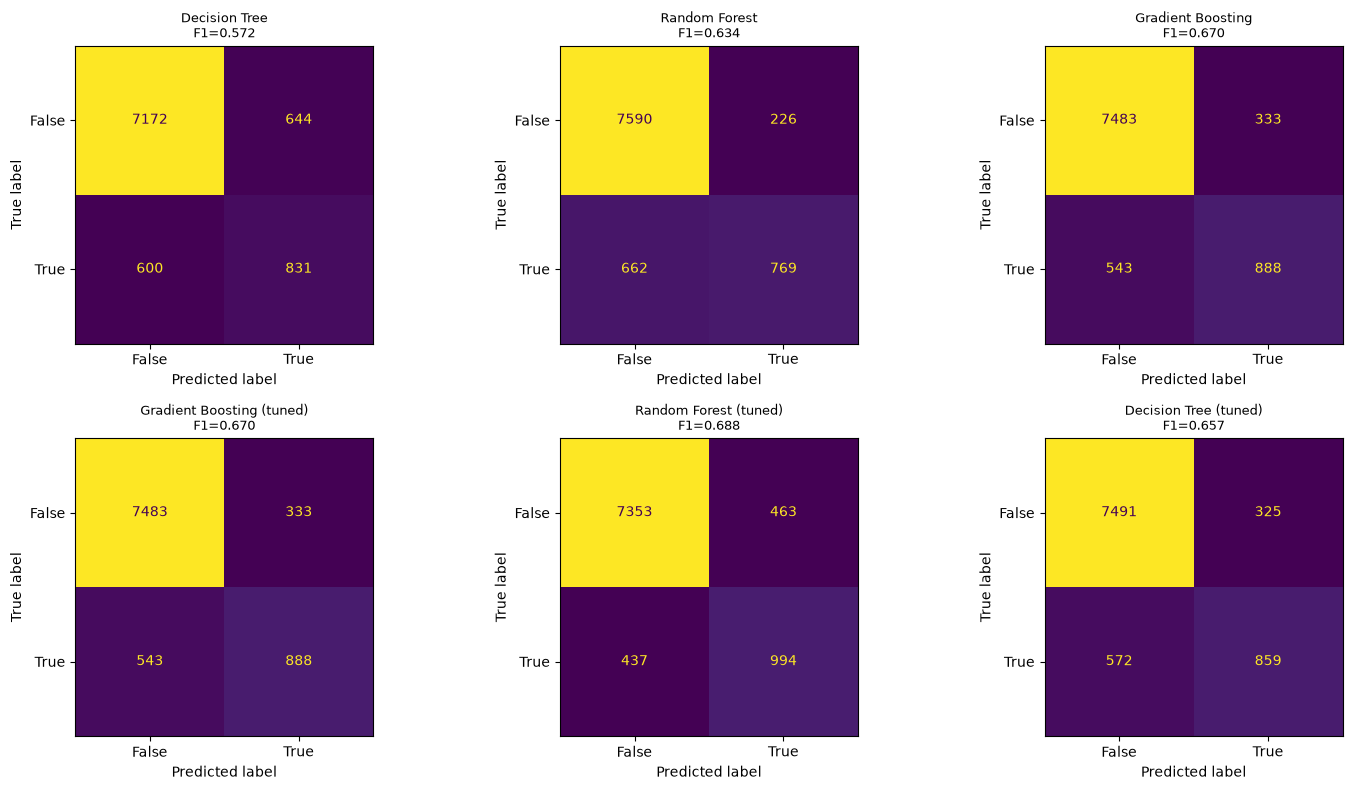

In [8]:
oof_models = {
    **{name: baseline_pipelines[name] for name in baseline_pipelines},
    **{f"{name} (tuned)": estimator for name, estimator in tuned_pipelines.items()},
}

oof_rows = []
oof_predictions = {}

for name, estimator in oof_models.items():
    pred = cross_val_predict(
        estimator,
        X,
        y,
        cv=cv,
        n_jobs=-1,
        method="predict",
    )
    oof_predictions[name] = pred
    oof_rows.append({
        "Model": name,
        "F1 (Revenue=True)": f1_score(y, pred, pos_label=True, zero_division=0),
        "Precision": precision_score(y, pred, pos_label=True, zero_division=0),
        "Recall": recall_score(y, pred, pos_label=True, zero_division=0),
    })

oof_results = pd.DataFrame(oof_rows).sort_values(
    "F1 (Revenue=True)", ascending=False
).reset_index(drop=True)
display(oof_results.style.format({
    "F1 (Revenue=True)": "{:.4f}",
    "Precision": "{:.4f}",
    "Recall": "{:.4f}",
}))

n_models = len(oof_predictions)
ncols = 3
nrows = int(np.ceil(n_models / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4 * nrows))
axes = np.array(axes).reshape(-1)

for ax, (name, pred) in zip(axes, oof_predictions.items()):
    ConfusionMatrixDisplay.from_predictions(
        y, pred, ax=ax, colorbar=False, values_format="d"
    )
    ax.set_title(
        f"{name}\nF1={f1_score(y, pred, pos_label=True, zero_division=0):.3f}",
        fontsize=9
    )

for ax in axes[n_models:]:
    ax.axis("off")

plt.tight_layout()
plt.show()


## 9. Model comparison and conclusion

Baseline and tuned versions of the three models on the same folds, sorted by CV F1 for `Revenue=True`.

In [9]:
comparison = baseline_results[["Model", "Train F1", "CV F1", "Train-CV gap"]].copy()
comparison["Stage"] = "Baseline"

if not tuned_results.empty:
    tuned_comparison = tuned_results[["Model", "Train F1", "CV F1", "Train-CV gap"]].copy()
    tuned_comparison["Stage"] = "Tuned"
    comparison = pd.concat([comparison, tuned_comparison], ignore_index=True)

comparison = comparison[["Model", "Stage", "Train F1", "CV F1", "Train-CV gap"]]
display(comparison.sort_values("CV F1", ascending=False).style.format({
    "Train F1": "{:.4f}",
    "CV F1": "{:.4f}",
    "Train-CV gap": "{:.4f}",
}))

best_oof = oof_results.iloc[0]
print(
    f"Highest OOF F1 in this notebook: {best_oof['Model']} "
    f"(F1={best_oof['F1 (Revenue=True)']:.4f}, "
    f"precision={best_oof['Precision']:.4f}, "
    f"recall={best_oof['Recall']:.4f})"
)


,Model,Stage,Train F1,CV F1,Train-CV gap
3,Random Forest,Tuned,0.9436,0.6884,0.2553
0,Gradient Boosting,Baseline,0.7342,0.6697,0.0644
4,Gradient Boosting,Tuned,0.7342,0.6697,0.0644
5,Decision Tree,Tuned,0.6745,0.6569,0.0175
1,Random Forest,Baseline,1.0000,0.6338,0.3662
2,Decision Tree,Baseline,1.0000,0.5716,0.4284


Highest OOF F1 in this notebook: Random Forest (tuned) (F1=0.6884, precision=0.6822, recall=0.6946)


### Conclusions

- **The tuned Random Forest is the strongest tree-based model (CV F1 = 0.688).** The baseline forest is precise but misses almost half of the purchases (precision 0.773, recall 0.537). Balanced class weights and `min_samples_leaf=2` move it to precision 0.682 and recall 0.695, which raises F1 from 0.634 to 0.688. Its train-CV gap stays large (0.255, down from 0.366), which is typical for a forest of deep trees.
- **Gradient Boosting: Grid Search selected the default configuration** (100 trees, learning rate 0.1, depth 3, no subsampling) out of 32, so the tuned and the baseline model are the same (CV F1 = 0.670). It favors precision (0.727) over recall (0.621) and has a small train-CV gap (0.064).
- **The Decision Tree gained the most from tuning (0.572 to 0.657).** The unpruned baseline tree memorizes the training data (train F1 = 1.000, gap 0.428). A tree limited to depth 4 with at least 10 sessions per leaf no longer overfits (train F1 = 0.674, gap 0.018). It is only 0.03 below the Random Forest and can be read as a small set of rules.
- **Class weights** helped the Random Forest. The best Decision Tree does not use them.
- **Runtime** is not a constraint: each Grid Search finishes in well under a minute.

**Recommendation:** the tuned Random Forest is the tree-based candidate for the final model, because it has the highest CV F1 and the best balance between precision and recall. The tuned Decision Tree is the interpretable alternative. The comparison with the other four required models is in `04_final_model.ipynb`.

## 10. Notes for the team

- `ID` is excluded from the predictors.
- The test dataset was not used for training, cross-validation, or tuning.
- The shared grouped folds and positive-class F1 scorer are used throughout.
- All three models are tuned and evaluated on the same folds, so the tuned scores are slightly optimistic. The final comparison of all seven models and the final model selection are in `04_final_model.ipynb`.
- This notebook does **not** create `predictions.csv`; it is written by `04_final_model.ipynb`.
